# Exploratory Data Analysis: Macroeconomic Drivers of Consumer Loan Delinquency

## Objective

In this part, we provide an initial exploration of the main variables used in the analysis. The goal here is to understand:

- What each variable represents
- How they evolve over time
- How they behave during major economic downturns
- How they can help us reach the goal of effectively predicting loan delinquency rates

This notebook is intentionally kept non-technical to focus on intuition and interpretation, and make it as understandable as possible.

*Data: quarterly series from FRED (1987 Q1 – 2025 Q4), built by `src/build_dataset.py`.*

We will first begin with the setup.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Quarterly dataset built from FRED by src/build_dataset.py
data = pd.read_csv("../data/data.csv", index_col="date", parse_dates=True)

delinq = data["delinquency"]
spread = data["yield_spread"]
unemp = data["unemployment"]
fedfunds = data["federal_fund_rate"]
sent = data["consumer_confidence"]

data.tail()

,delinquency,yield_spread,unemployment,federal_fund_rate,consumer_confidence
date,,,,,
2024-12-31,2.76,0.130000,4.133333,4.650000,72.100000
2025-03-31,2.77,0.304918,4.133333,4.330000,64.466667
2025-06-30,2.76,0.500000,4.200000,4.330000,55.033333
2025-09-30,2.71,0.540312,4.333333,4.293333,58.333333
2025-12-31,2.62,0.577581,4.450000,3.896667,52.500000


Setup to shade the recession periods in each of the graphs.

In [2]:
# NBER US business-cycle recessions (peak month to trough month) within the sample
RECESSIONS = [
    ("1990-07-01", "1991-03-31"),
    ("2001-03-01", "2001-11-30"),
    ("2007-12-01", "2009-06-30"),
    ("2020-02-01", "2020-04-30"),
]


def shade_recessions(ax):
    for start, end in RECESSIONS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.2)


def plot_with_recessions(series, title, ylabel, figsize=(11, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(series.index, series.values)
    shade_recessions(ax)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    plt.show()

## Our Target Variable: Consumer Loan Delinquency Rate

This is the variable at the center of our analysis, and it measures the percentage of consumer loans that are past due. In practice, it is measured across different thresholds, namely 30, 60, or 90 days past due; and the aggregate rate we use here captures all of them. This means our variable reflects a spectrum of financial distress, from early warning signs to near-default situations.

This variable can be considered as a strong signal of system-wide financial stress, as well as future credit losses. But one of its most interesting properties is its dual temporal nature. It tends to lag the initial economic shock, while leading the actual credit losses that eventually show up; giving institutions a window to act before the damage is fully done.

Therefore, predicting the consumer loan delinquency rate can help various different actors. Central banks monitor it to calibrate monetary policy, prudential regulators use it in stress testing exercises, and fiscal authorities track it to anticipate rising demand for social safety nets. In short, this one variable sits at the intersection of monetary policy, financial stability, and household welfare.

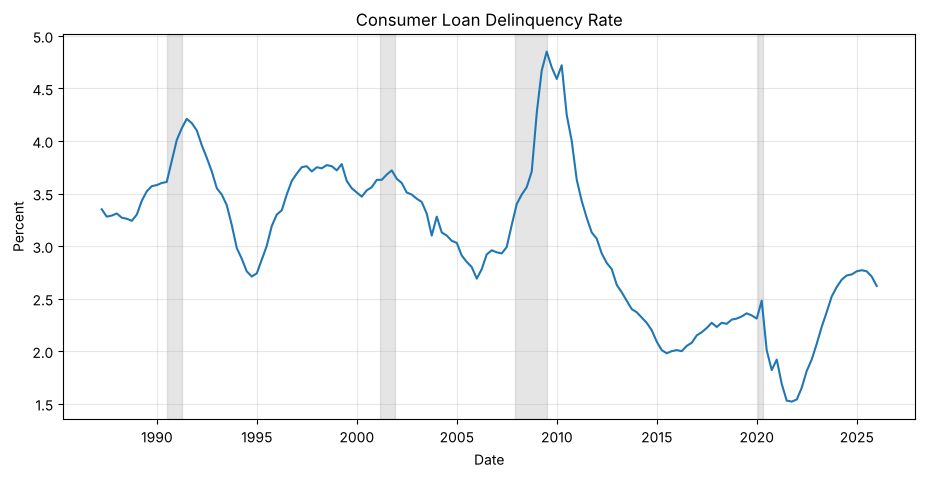

In [3]:
plot_with_recessions(delinq, "Consumer Loan Delinquency Rate", "Percent")

### Interpretation

Here we can see that this variable pretty much behaves as expected, sharply increasing during economic downturns as difficult conditions make it harder for people to repay their loans; being at its highest in 2009 as a result of the financial crisis.

This is true except in one instance, during the COVID-19 pandemic (represented by the last recession shaded area) where we see the loan delinquency rate get to its lowest percentage. This can be explained by various policy interventions put in place at the time, reflecting the impact of government programs as well as direct transfers (e.g. stimulus checks) on debt servicing capacity.

These facts show that our variable is influenced by both economic conditions and policy responses. But more importantly, that the period after 2020 can skew the results of our analysis. This will be taken into account and tackled in the feature engineering part of our analysis.

## Predicting Variables

Here, the various predictors are organized around three theoretical transmission channels linking the business cycle to consumer credit stress:

- **Monetary policy conditions**, captured by the federal funds rate and the yield curve spread;
- **Real economy shocks**, captured by unemployment;
- **Household expectations**, captured by consumer confidence.

### Yield Curve Spread (10Y - 2Y)

Simply put, this variable measures how much higher or lower the long-term interest rate is compared to a short-term interest rate. It is widely considered a leading indicator of economic activity:

- Positive values (long-term rates > short-term rates) reflect normal conditions
- Negative values or inversions often precede recessions

The yield curve spread can be considered as an early warning signal, as it reflects what markets generally expect about the economy. This variable will capture the expectations part of our macroeconomic modeling.

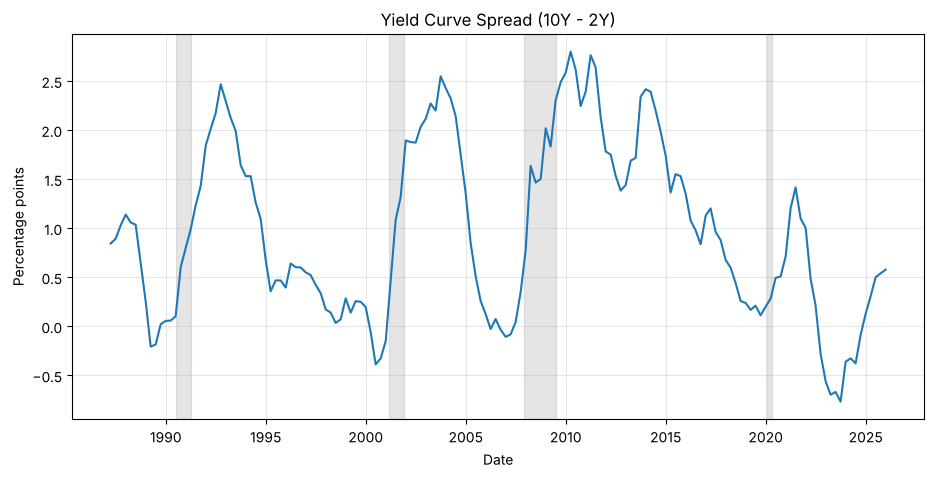

In [4]:
plot_with_recessions(spread, "Yield Curve Spread (10Y - 2Y)", "Percentage points")

#### Interpretation

- The spread fluctuates around zero and occasionally becomes negative
- These inversions appear before major economic downturns
- This supports its role as a forward-looking indicator

### Unemployment Rate

The unemployment rate reflects labor market conditions. Intuitively, a higher unemployment rate means a reduction in household income and an increase in the risk of missed loan payments.

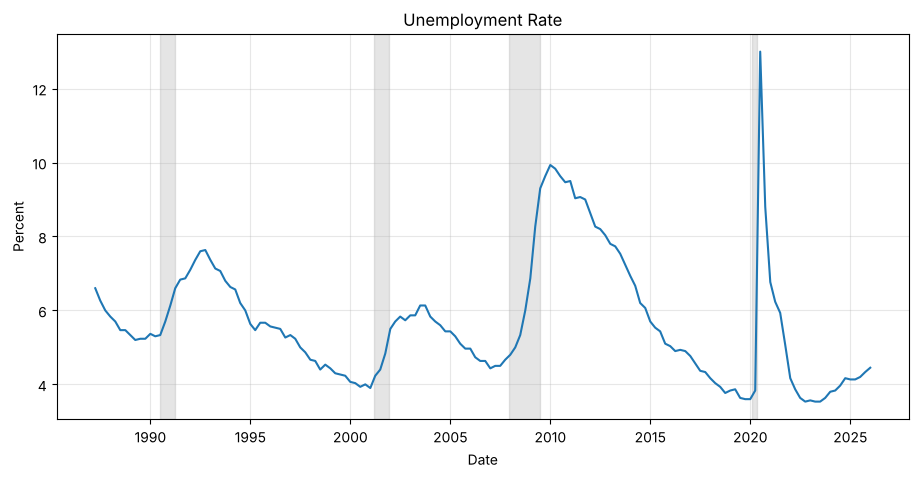

In [5]:
plot_with_recessions(unemp, "Unemployment Rate", "Percent")

#### Interpretation

- The series shows sharp spikes during recessions
- It reacts strongly during crises rather than anticipating them
- This suggests it behaves more as a lagging or coincident indicator

### Federal Funds Rate

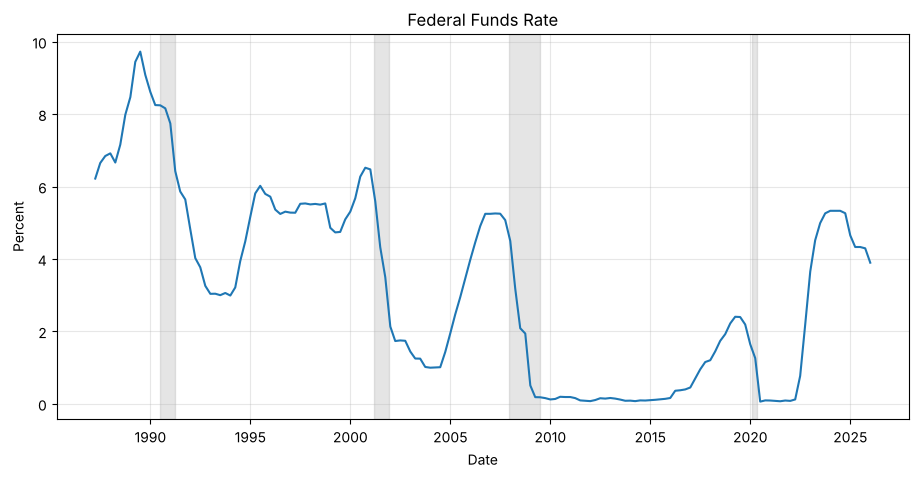

In [6]:
plot_with_recessions(fedfunds, "Federal Funds Rate", "Percent")

#### Interpretation

- The series reflects monetary policy cycles
- It is more volatile than other variables
- Its effect on households is likely delayed rather than immediate

### Consumer Confidence (UMCSENT)

This variable reflects households' expectations about the economy. Lower confidence may signal:

- reduced spending
- increased precautionary saving
- potential future financial stress

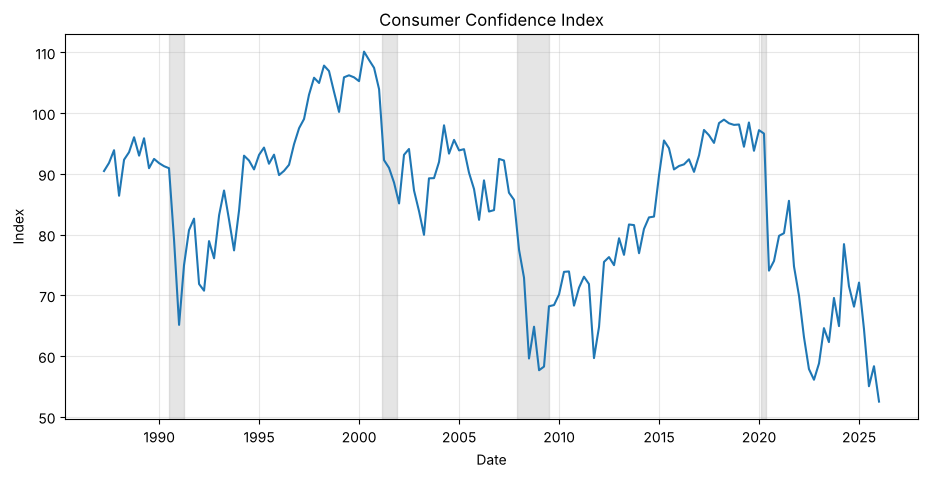

In [7]:
plot_with_recessions(sent, "Consumer Confidence Index", "Index")

#### Interpretation

- Confidence tends to decline before or during downturns
- It captures expectations rather than realized economic conditions
- This makes it a potentially useful leading indicator

## Stylized Facts

From the exploratory analysis, several patterns emerge:

- Delinquency is relatively stable but spikes during major crises
- The yield curve spread often deteriorates before downturns
- Unemployment reacts strongly during recessions
- Consumer confidence declines ahead of or during stress periods
- Interest rates reflect broader monetary policy cycles

These observations suggest that macroeconomic conditions may provide useful signals for predicting future credit stress.

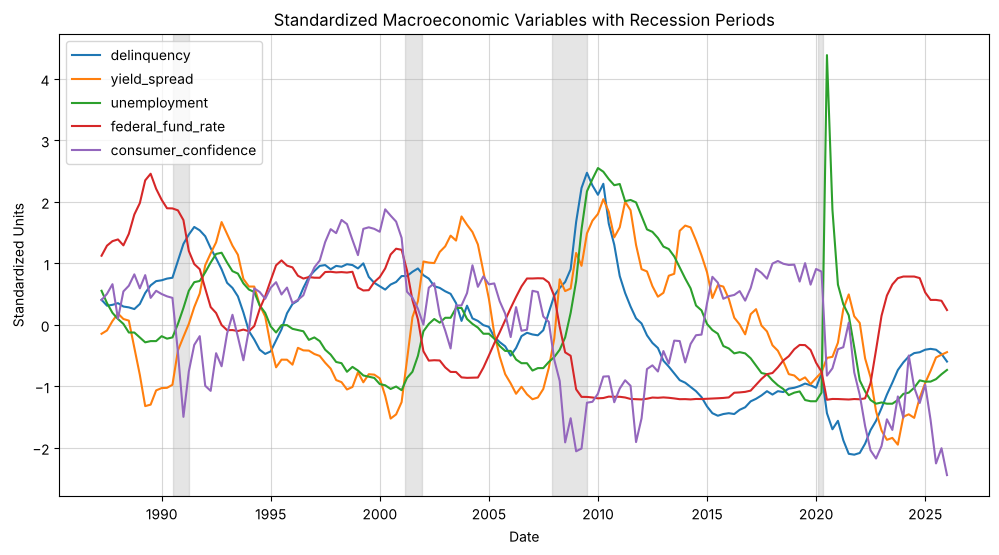

In [8]:
# Standardize all series so they can be compared on one chart
overview_std = (data - data.mean()) / data.std()

fig, ax = plt.subplots(figsize=(12, 6))
for col in overview_std.columns:
    ax.plot(overview_std.index, overview_std[col], label=col)
shade_recessions(ax)

ax.set_title("Standardized Macroeconomic Variables with Recession Periods")
ax.set_xlabel("Date")
ax.set_ylabel("Standardized Units")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()